# Wearable Activity Recognition
## Generalization to unseen people
**Dr. Şeyma Bozkurt Uzan · Biomedical Engineering / Machine Learning**

**Engineering question:** How well do smartphone motion features recognize six activities in people who were not used to train the model? What changes when we use only 18 accelerometer features instead of all 561 features?

The analysis workflow is **biomedical question → methods → implementation → controlled comparison → biomedical interpretation**. The goal is to explain a reproducible engineering comparison, including its limitations.

This notebook runs on a CPU. The first run downloads about 61 MB from UCI; subsequent runs reuse the verified archive. A complete run includes 40 training-fold fits and the final evaluation. No paid Colab or GPU is required.

### 1 · Data and intended use
The [UCI Human Activity Recognition Using Smartphones dataset](https://doi.org/10.24432/C54S4K) contains waist-mounted smartphone measurements from 30 volunteers. It covers walking, walking upstairs, walking downstairs, sitting, standing and lying. Accelerometer and gyroscope recordings were sampled at 50 Hz; 2.56-second windows overlap by 50%. The released table contains 561 engineered features.

The official split separates **21 training participants from 9 test participants**. Our task is activity monitoring under this acquisition protocol. The data contain no clinical outcome, so the experiment cannot establish rehabilitation efficacy or diagnose disease.

**Source and reuse:** The current UCI landing page lists CC BY 4.0; the historical archive README includes different commercial-use wording. This project downloads from the original provider and does not redistribute or relicense the data. See `DATA_LICENSE.md` for provenance and the discrepancy. The original study is [Anguita et al., ESANN 2013](https://www.esann.org/sites/default/files/proceedings/legacy/es2013-84.pdf).

In [1]:
# Run this cell in Colab or from the cloned repository.
from pathlib import Path
import importlib.util
import os
import subprocess
import sys

REPOSITORY_URL = "https://github.com/Seymabu/wearable-activity-analysis.git"
cwd = Path.cwd()
candidates = [cwd, *cwd.parents, cwd / "wearable-activity-analysis",
              Path("/content/wearable-activity-analysis")]
PROJECT_ROOT = next((p for p in candidates if (p / "src/analysis.py").is_file()), None)
if PROJECT_ROOT is None:
    PROJECT_ROOT = cwd / "wearable-activity-analysis"
    subprocess.run(["git", "clone", REPOSITORY_URL, str(PROJECT_ROOT)], check=True)

required_modules = ["numpy", "pandas", "scipy", "sklearn", "matplotlib", "threadpoolctl"]
if any(importlib.util.find_spec(m) is None for m in required_modules):
    subprocess.run([sys.executable, "-m", "pip", "install", "-r",
                    str(PROJECT_ROOT / "requirements.txt")], check=True)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
DATA_DIR = Path(os.environ.get("WEARABLE_DATA_DIR", PROJECT_ROOT / "data"))
RESULTS_DIR = PROJECT_ROOT / "results"
print("Project code located. CPU workflow ready.")

Project code located. CPU workflow ready.


In [2]:
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
from sklearn.model_selection import StratifiedGroupKFold
from src.analysis import (load_data, run_analysis, compact_feature_indices,
                          validate_subject_split, make_classifier, SEED, C_GRID)

data = load_data(DATA_DIR)
validate_subject_split(data.subject_train, data.subject_test)
audit = pd.DataFrame({
    "split": ["Training", "Held-out test"],
    "windows": [len(data.y_train), len(data.y_test)],
    "participants": [len(np.unique(data.subject_train)), len(np.unique(data.subject_test))],
    "features": [data.X_train.shape[1], data.X_test.shape[1]],
    "nonfinite_values": [int((~np.isfinite(data.X_train)).sum()),
                         int((~np.isfinite(data.X_test)).sum())],
})
display(audit)
print("Overlapping participant IDs:", sorted(set(data.subject_train) & set(data.subject_test)))
print("Repeated original feature names:", int(data.features.original_name.duplicated().sum()))
print("Unique indexed names preserved:", data.features.unique_name.is_unique)
print("Original payload checksum verified:", data.provenance["payload_hash_verified"])

Overlapping participant IDs: []
Repeated original feature names: 84
Unique indexed names preserved: True
Original payload checksum verified: True


Matplotlib is building the font cache; this may take a moment.


,split,windows,participants,features,nonfinite_values
0,Training,7352,21,561,0
1,Held-out test,2947,9,561,0


**Interpretation.** One row is a short time window, not an independent person. Neighboring windows overlap. A random window split can put closely related measurements from the same person on both sides of evaluation. The official participant split addresses that problem for this study.

The archive contains repeated feature names. We keep the original column index in every unique name so that a dictionary or table operation cannot silently overwrite a feature.

**Measurement caution:** The source already filtered, engineered and normalized its feature columns. Their values should not be read as raw acceleration in g or angular velocity in radians/second. We can verify training-only fitting of the additional scaler below; we cannot reconstruct the training provenance of every upstream transformation.

### 2 · Baselines, metrics and validation
A most-frequent classifier predicts the training set's most common activity. It tells us how little a model can achieve without using motion features.

The learned model is multiclass logistic regression: a linear score for each activity is converted to class probabilities. The regularization parameter `C` controls the fit/complexity tradeoff. Scaling and model fitting belong inside each training fold.

We select `C` from `[0.01, 0.1, 1, 10]` using five folds of **training participants only**. Each training person contributes one validation score per candidate; participants receive equal weight even when fold sizes differ. The held-out test people are not used to choose `C` or features.

Our primary metric is the **mean of participant-level macro-F1 scores**, computed over the same six labels. Macro-F1 gives equal weight to activity classes within a person; averaging those scores gives equal weight to people. Pooled accuracy and pooled macro-F1 answer related but different questions.

In [3]:
# Inspect the validation design before fitting any model.
folds = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
             .split(data.X_train, data.y_train, groups=data.subject_train))
fold_audit = []
for fold_number, (fit_rows, validation_rows) in enumerate(folds, start=1):
    fit_people = np.unique(data.subject_train[fit_rows])
    validation_people = np.unique(data.subject_train[validation_rows])
    validate_subject_split(fit_people, validation_people)
    fold_audit.append({"fold": fold_number,
                       "training_people": len(fit_people),
                       "validation_people": len(validation_people),
                       "overlap": len(set(fit_people) & set(validation_people))})
display(pd.DataFrame(fold_audit))
print("C grid:", C_GRID)
print("Pipeline fitted separately within each fold:")
print(make_classifier(c_value=1.0))

C grid: (0.01, 0.1, 1.0, 10.0)
Pipeline fitted separately within each fold:
Pipeline(steps=[('scale', StandardScaler()),
                ('logistic',
                 LogisticRegression(max_iter=3000, random_state=571))])


,fold,training_people,validation_people,overlap
0,1,17,4,0
1,2,17,4,0
2,3,16,5,0
3,4,17,4,0
4,5,17,4,0


### 3 · One controlled extension: a compact representation
We specify 18 features **before test evaluation**: mean and standard deviation of X/Y/Z for body acceleration, gravity acceleration and body-acceleration jerk. Gyroscope and mixed angle features are excluded.

Both feature sets use the same classifier family, the same participant folds and the same `C` candidates. Each representation selects its own regularization strength on training people. This compares two complete, prespecified pipelines; it is not a causal estimate of the gyroscope's isolated effect.

The motivation is device simplification. Fewer inputs do not prove lower battery use or shorter runtime; those quantities require measurement.

In [4]:
compact_indices = compact_feature_indices(data.features)
compact_features = data.features.iloc[compact_indices].copy()
display(compact_features)
print(f"Full representation: {data.X_train.shape[1]} features")
print(f"Compact representation: {len(compact_indices)} features")
print(f"Feature-count reduction: {1 - len(compact_indices) / data.X_train.shape[1]:.1%}")

Full representation: 561 features
Compact representation: 18 features
Feature-count reduction: 96.8%


,feature_index,original_name,unique_name
0,1,tBodyAcc-mean()-X,001__tBodyAcc-mean()-X
1,2,tBodyAcc-mean()-Y,002__tBodyAcc-mean()-Y
2,3,tBodyAcc-mean()-Z,003__tBodyAcc-mean()-Z
3,4,tBodyAcc-std()-X,004__tBodyAcc-std()-X
4,5,tBodyAcc-std()-Y,005__tBodyAcc-std()-Y
5,6,tBodyAcc-std()-Z,006__tBodyAcc-std()-Z
40,41,tGravityAcc-mean()-X,041__tGravityAcc-mean()-X
41,42,tGravityAcc-mean()-Y,042__tGravityAcc-mean()-Y
42,43,tGravityAcc-mean()-Z,043__tGravityAcc-mean()-Z
43,44,tGravityAcc-std()-X,044__tGravityAcc-std()-X


### 4 · Run the complete experiment
The function below carries out grouped tuning, fits the chosen models on all training people, then evaluates the fixed test set. It records dataset hashes, software versions, fold assignments, selected parameters, metrics and figures in `results/`.

Uncertainty uses 2,000 **paired participant-bootstrap** samples: a sampled person contributes their scores for both learned models together. This preserves the comparison pairing and does not treat overlapping windows as independent observations. With only nine test people, the intervals are descriptive and conditional on these fitted models and this split; they do not include retraining uncertainty.

In [5]:
metrics = run_analysis(DATA_DIR, RESULTS_DIR)
print("Experiment complete. See results/ for reproducibility records.")

Tuning full_logistic on training participants only...
Tuning compact_logistic on training participants only...
           model  n_features  selected_C  mean_subject_macro_f1   ci_low  ci_high  pooled_macro_f1  pooled_accuracy  pooled_balanced_accuracy
           dummy           0         NaN               0.051269 0.049318 0.052923         0.051378         0.182219                  0.166667
   full_logistic         561         1.0               0.951819 0.922897 0.977239         0.954675         0.954869                  0.953495
compact_logistic          18         0.1               0.818263 0.730400 0.897135         0.839073         0.842891                  0.837823
Experiment complete. See results/ for reproducibility records.


In [6]:
summary = pd.DataFrame(metrics["models"])
columns = ["model", "n_features", "selected_C", "mean_subject_macro_f1",
           "ci_low", "ci_high", "pooled_macro_f1", "pooled_accuracy"]
display(summary[columns].round(4))
print("Training-only parameter selection:")
display(pd.DataFrame(metrics["selection"]["chosen"]).T.round(4))
delta = metrics["compact_minus_full"]
print(f"Compact minus full mean participant macro-F1: {delta['mean_difference']:.4f}")
print(f"Paired 95% interval: [{delta['ci_low']:.4f}, {delta['ci_high']:.4f}]")

Training-only parameter selection:
Compact minus full mean participant macro-F1: -0.1336
Paired 95% interval: [-0.1993, -0.0703]


,model,n_features,selected_C,mean_subject_macro_f1,ci_low,ci_high,pooled_macro_f1,pooled_accuracy
0,dummy,0,NaN,0.0513,0.0493,0.0529,0.0514,0.1822
1,full_logistic,561,1.0,0.9518,0.9229,0.9772,0.9547,0.9549
2,compact_logistic,18,0.1,0.8183,0.7304,0.8971,0.8391,0.8429


,C,training_cv_mean_subject_macro_f1
full_logistic,1.0,0.9345
compact_logistic,0.1,0.8688


### 5 · Read the figures as engineering evidence
Begin with the acquisition and sampling picture, then evaluate errors and variation across people. The PCA view uses training data only; visible separation is exploratory evidence, not a substitute for held-out evaluation.

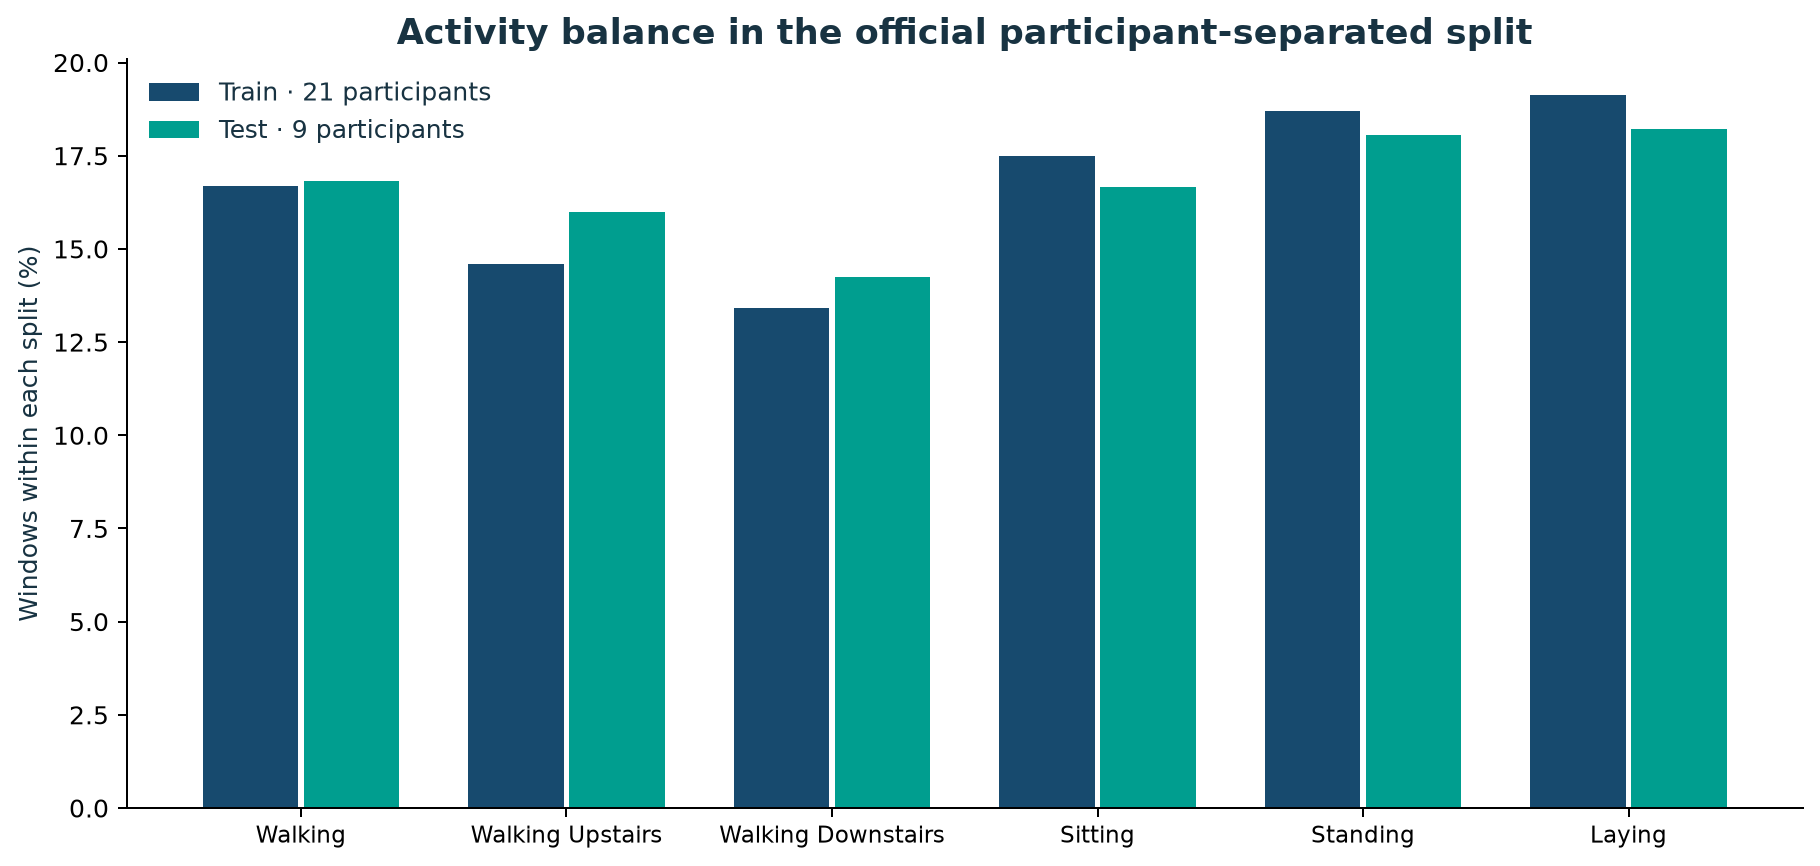

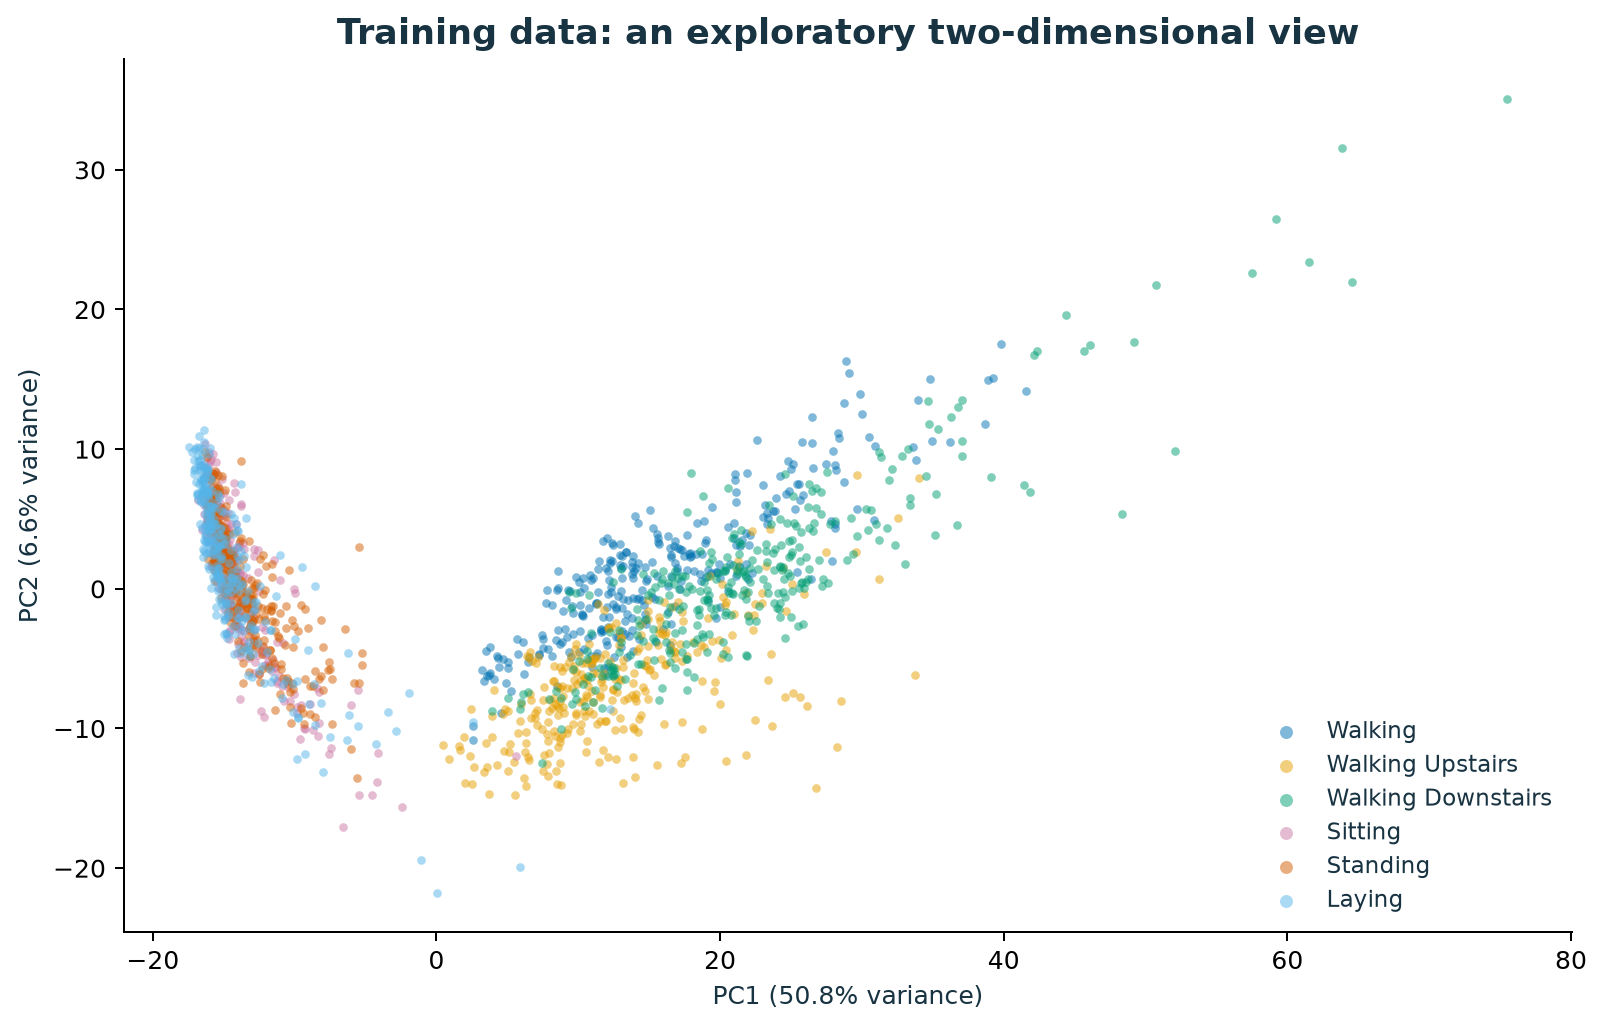

In [7]:
display(Image(filename=str(RESULTS_DIR / "figures/01_activity_balance.png"), width=950))
display(Image(filename=str(RESULTS_DIR / "figures/02_training_pca.png"), width=850))

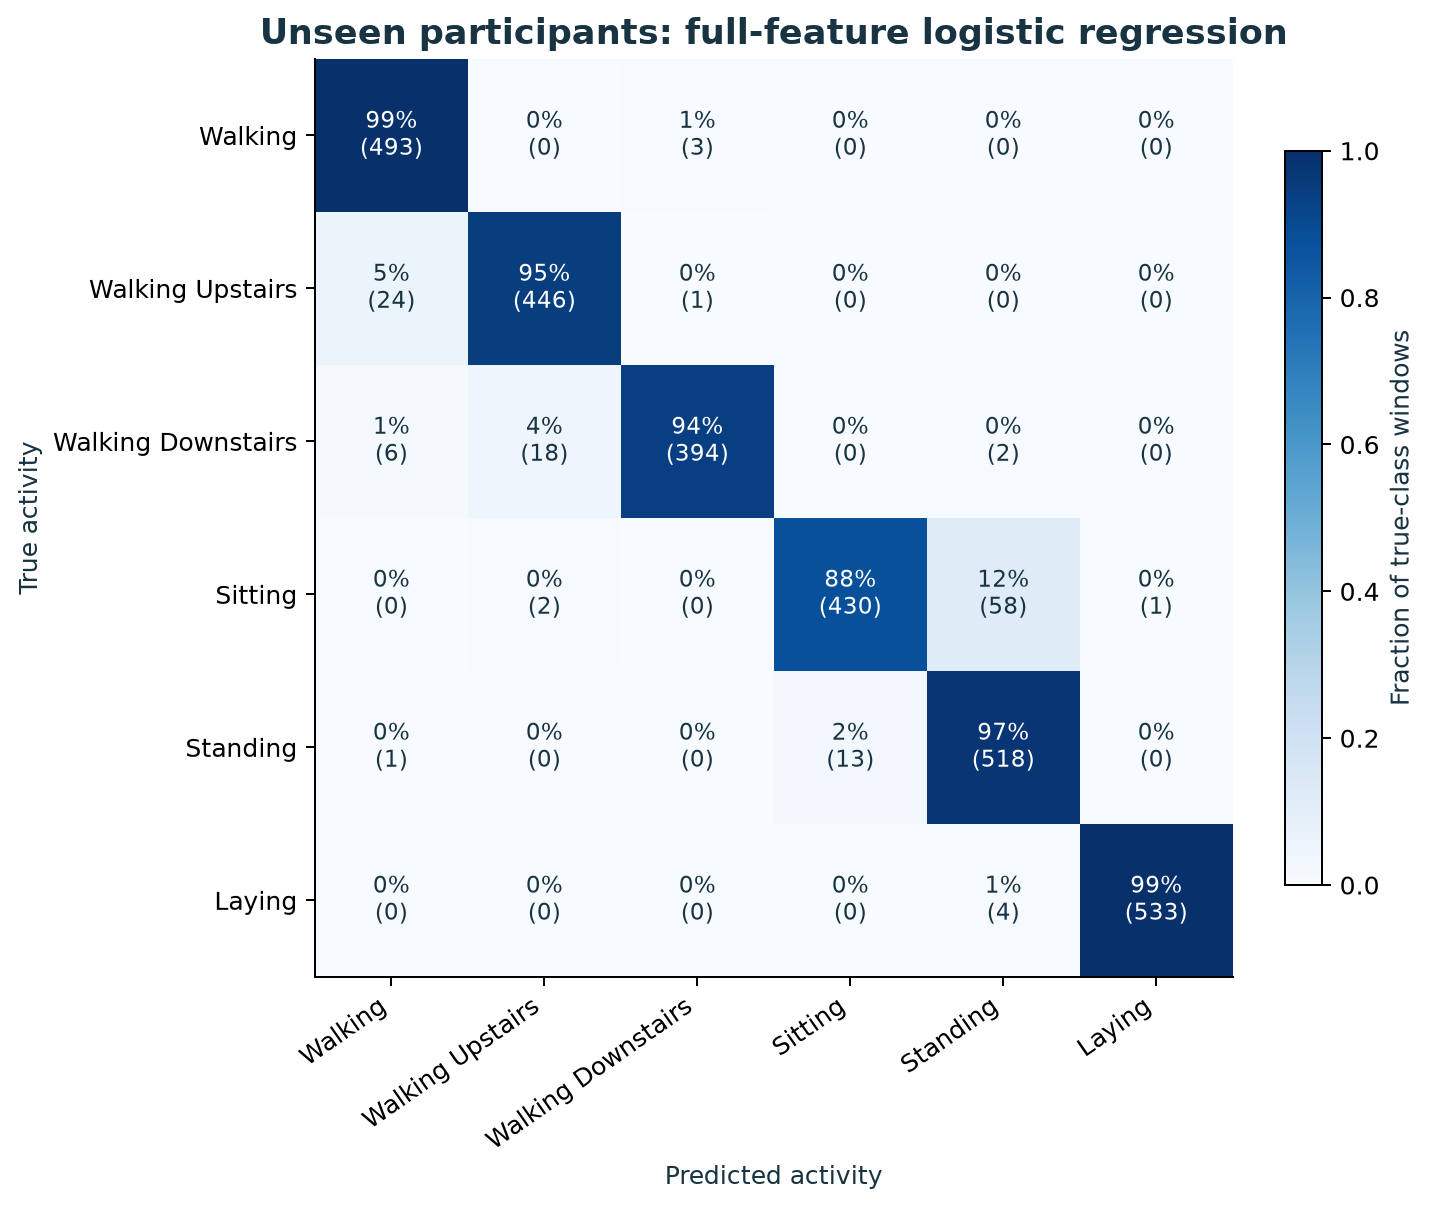

,precision,recall,f1-score,support
WALKING,0.9408,0.9940,0.9667,496.0
WALKING_UPSTAIRS,0.9571,0.9469,0.9520,471.0
WALKING_DOWNSTAIRS,0.9899,0.9381,0.9633,420.0
SITTING,0.9707,0.8758,0.9208,491.0
STANDING,0.8900,0.9737,0.9300,532.0
LAYING,0.9981,0.9926,0.9953,537.0


In [8]:
display(Image(filename=str(RESULTS_DIR / "figures/03_confusion_matrix.png"), width=850))
full_report = pd.DataFrame(metrics["class_reports"]["full_logistic"]).T
activity_rows = [data.activity_names[i] for i in range(1, 7)]
display(full_report.loc[activity_rows, ["precision", "recall", "f1-score", "support"]].round(4))

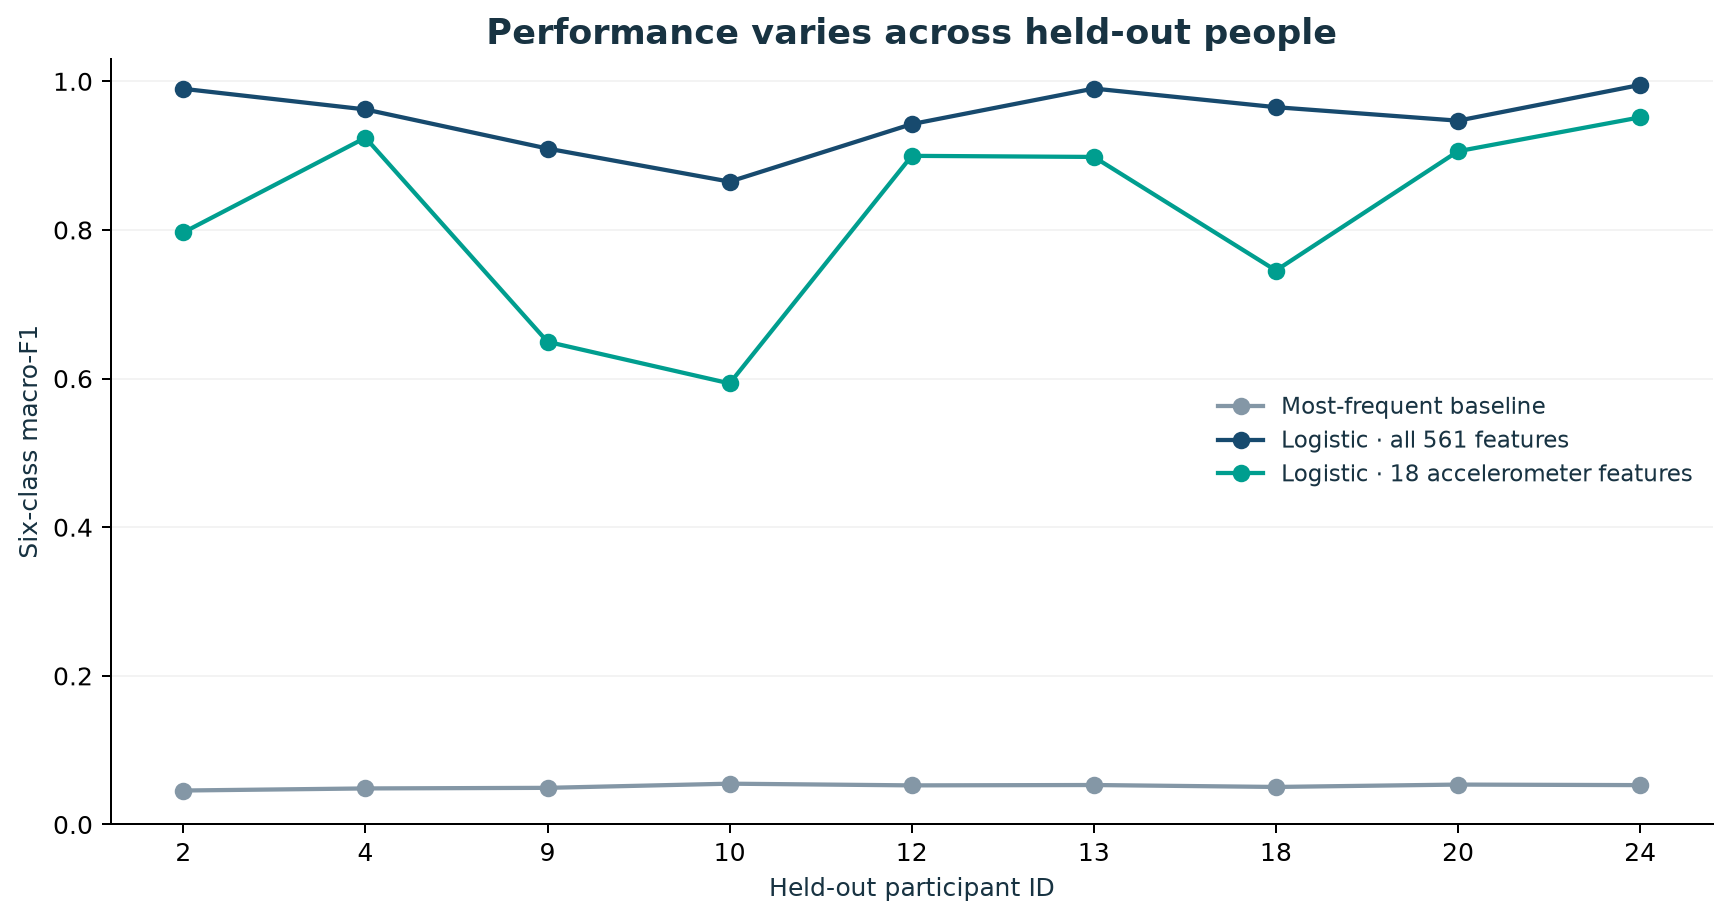

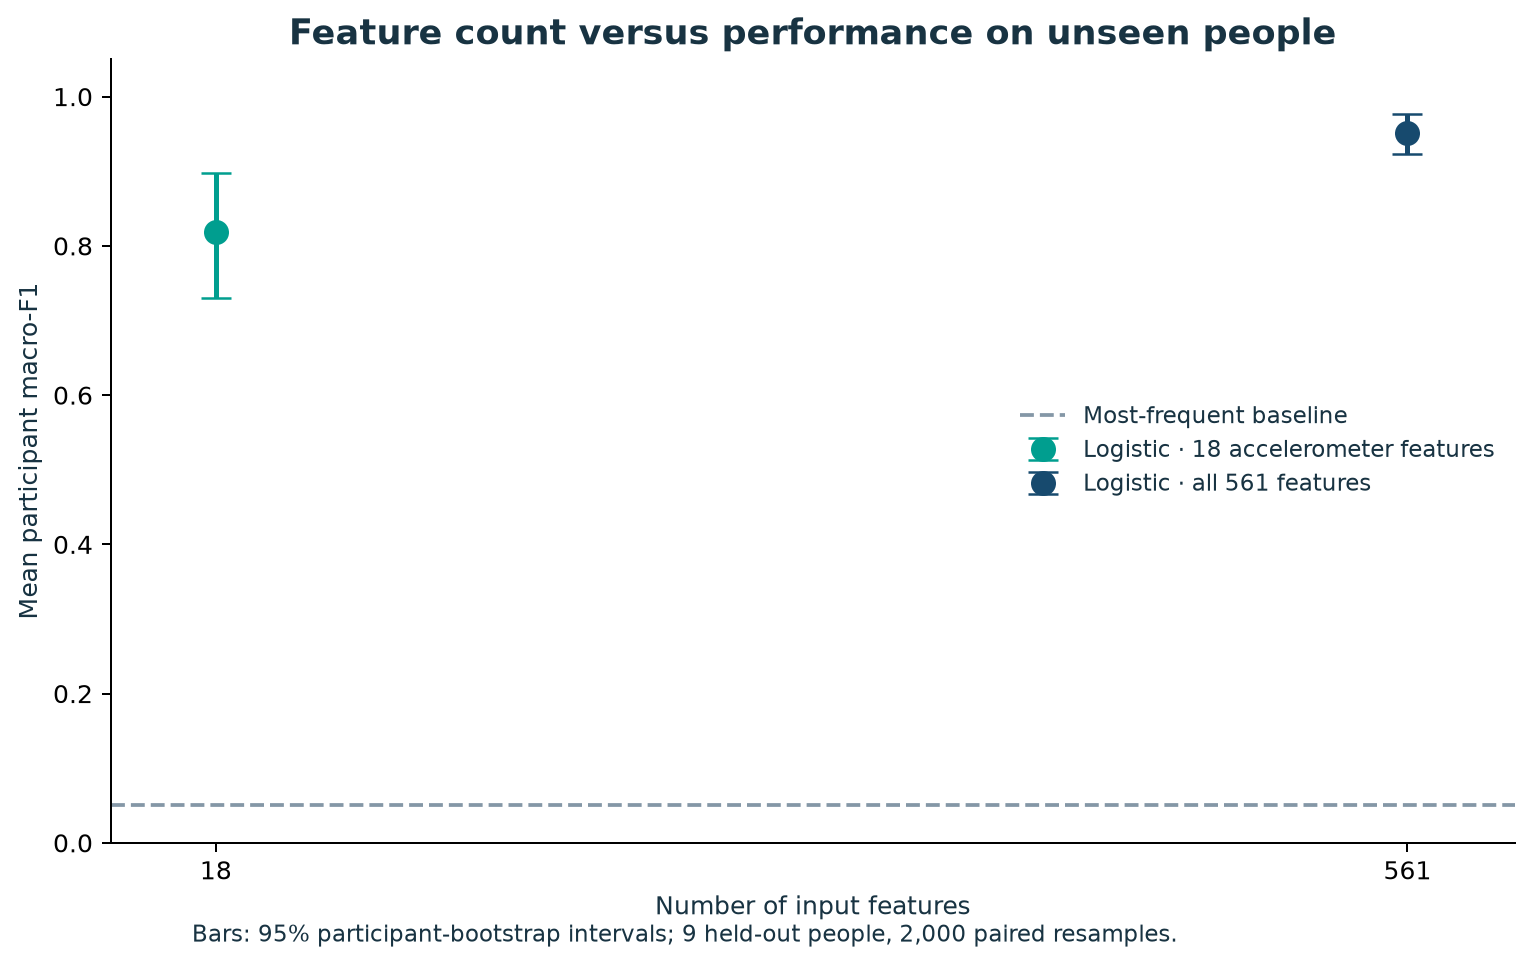

model,compact_logistic,dummy,full_logistic
subject_id,,,
2,0.7966,0.0457,0.9899
4,0.9241,0.0485,0.9621
9,0.6495,0.0493,0.9095
10,0.5935,0.0549,0.8650
12,0.8997,0.0526,0.9424
13,0.8982,0.0531,0.9902
18,0.7454,0.0505,0.9652
20,0.9059,0.0537,0.9470
24,0.9515,0.0530,0.9951


In [9]:
display(Image(filename=str(RESULTS_DIR / "figures/04_participant_performance.png"), width=950))
display(Image(filename=str(RESULTS_DIR / "figures/05_features_vs_performance.png"), width=850))
per_person = pd.read_csv(RESULTS_DIR / "per_subject_metrics.csv")
display(per_person.pivot(index="subject_id", columns="model", values="macro_f1").round(4))

### 6 · Biomedical interpretation
The full feature pipeline performs better than the compact representation in this experiment. The compact pipeline substantially reduces the number of inputs, but its errors and between-person variation are larger. The comparison makes an engineering tradeoff visible; it does not demonstrate an acceptable device configuration for a particular clinical purpose.

Inspect the sitting/standing confusion and the participant-level figure. A high pooled score can conceal a poorer result for an individual person. A biomedical engineer would ask how phone placement, movement limitations, sensor noise and unscripted activities could change the outcome.

This benchmark has nine held-out people, a fixed waist-phone protocol and six scripted activities. It does not validate falls, disease detection, rehabilitation outcomes, other sensor placements or a clinical population. Further development needs fresh validation rather than repeated optimization against the same test set.

### 7 · Further investigation
Use the training participants to investigate **one** new design choice:

1. Compare a second, biologically motivated feature set or a linear support-vector classifier.
2. Record the choice and grouped validation plan before looking at its performance.
3. Keep preprocessing inside the training folds and report person-level validation variation.
4. Explain what changed and what it means for the intended monitoring task.

Because the test results in this notebook are now visible, additional exploration should report training-only grouped-validation results. A new confirmatory claim requires fresh held-out participants or another compatible dataset.

**Questions for further study:** Why is the participant the validation unit? Which errors matter for the chosen application? What additional evidence would you need before using the model outside the laboratory?

**Türkçe değerlendirme:** Aynı kişiden gelen zaman pencerelerini neden ayırmıyoruz? Özellik sayısını azaltmanın kazancı ve performans kaybı nedir? Bu sonuçların klinik kullanım için yeterli olmadığını hangi sınırlılıklar gösteriyor?

### Reproducibility and attribution
- Analysis author: **Dr. Şeyma Bozkurt Uzan**.
- Dataset: Reyes-Ortiz, Anguita, Ghio, Oneto and Parra (2013), [UCI HAR, DOI 10.24432/C54S4K](https://doi.org/10.24432/C54S4K).
- Methods implementation: [`src/analysis.py`](../src/analysis.py). Recorded results and versions: [`results/metrics.json`](../results/metrics.json).
- Validation reference: [scikit-learn StratifiedGroupKFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html).
- The notebook calls the same analysis used to generate the repository figures. No raw records, fitted model binary or personal credentials are included in the published repository.